# 01 — Exploring C-MAPSS FD001

**Goal of Week 1:** understand the data before modelling it.

- 100 training engines, each run until failure
- 1 operating condition (sea level), 1 fault mode: **HPC (high-pressure compressor) degradation**
- Per cycle: 3 operating settings + 21 sensors

Questions answered here:
1. How long do engines last?
2. Which sensors are flat (no information) and can be dropped?
3. Which sensors trend with degradation, and how strongly?

In [9]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.data_loader import load_train, load_test, SENSORS, label

FIG = Path('../reports/figures'); FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

train, test = load_train(), load_test()
train.head()

,unit,cycle,setting_1,setting_2,setting_3,s1,s2,s3,s4,s5,...,s13,s14,s15,s16,s17,s18,s19,s20,s21,rul
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,191
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,190
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,189
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,188
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,187


## 1. How long do engines last?

count    100.0
mean     206.3
std       46.3
min      128.0
25%      177.0
50%      199.0
75%      229.2
max      362.0
Name: cycle, dtype: float64


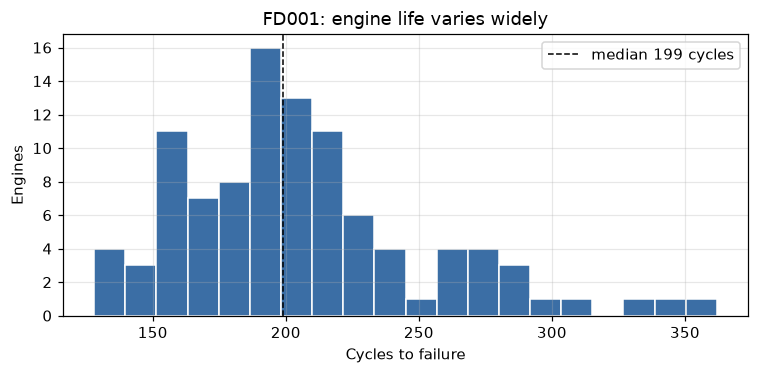

In [10]:
life = train.groupby('unit')['cycle'].max()
print(life.describe().round(1))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(life, bins=20, color='#3b6ea5', edgecolor='white')
ax.axvline(life.median(), color='k', ls='--', lw=1, label=f'median {life.median():.0f} cycles')
ax.set(xlabel='Cycles to failure', ylabel='Engines', title='FD001: engine life varies widely')
ax.legend(); fig.tight_layout(); fig.savefig(FIG / '01_engine_life.png')

## 2. Which sensors are flat?

A sensor that barely changes carries no information about health. Drop it.

In [11]:
sensor_cols = list(SENSORS)
stats = pd.DataFrame({
    'tag': [SENSORS[s][0] for s in sensor_cols],
    'meaning': [SENSORS[s][1] for s in sensor_cols],
    'std': train[sensor_cols].std().values,
    'unique_values': train[sensor_cols].nunique().values,
}, index=sensor_cols)
stats['flat'] = (stats['std'] < 1e-3) | (stats['unique_values'] <= 2)
stats.round(4)

,tag,meaning,std,unique_values,flat
s1,T2,Fan inlet total temperature,0.0000,1,True
s2,T24,LPC outlet total temperature,0.5001,310,False
s3,T30,HPC outlet total temperature,6.1311,3012,False
s4,T50,LPT outlet total temperature,9.0006,4051,False
s5,P2,Fan inlet pressure,0.0000,1,True
s6,P15,Bypass-duct total pressure,0.0014,2,True
s7,P30,HPC outlet total pressure,0.8851,513,False
s8,Nf,Physical fan speed,0.0710,53,False
s9,Nc,Physical core speed,22.0829,6403,False
s10,epr,Engine pressure ratio (P50/P2),0.0000,1,True


In [12]:
# Settings: with only one operating condition, settings 1-2 are noise and setting 3 is constant
train[['setting_1', 'setting_2', 'setting_3']].describe().round(4)

,setting_1,setting_2,setting_3
count,20631.0000,20631.0000,20631.0
mean,-0.0000,0.0000,100.0
std,0.0022,0.0003,0.0
min,-0.0087,-0.0006,100.0
25%,-0.0015,-0.0002,100.0
50%,0.0000,0.0000,100.0
75%,0.0015,0.0003,100.0
max,0.0087,0.0006,100.0


## 3. Which sensors trend with degradation?

Spearman correlation between each sensor and RUL (rank-based, so it catches non-linear trends).
Negative = sensor rises as the engine nears failure.

s11   -0.718
s4    -0.702
s12    0.693
s7     0.679
s15   -0.666
s21    0.657
s20    0.653
s17   -0.629
s2    -0.629
s3    -0.606
s8    -0.574
s13   -0.573
s9    -0.322
s14   -0.202
Name: rul, dtype: float64

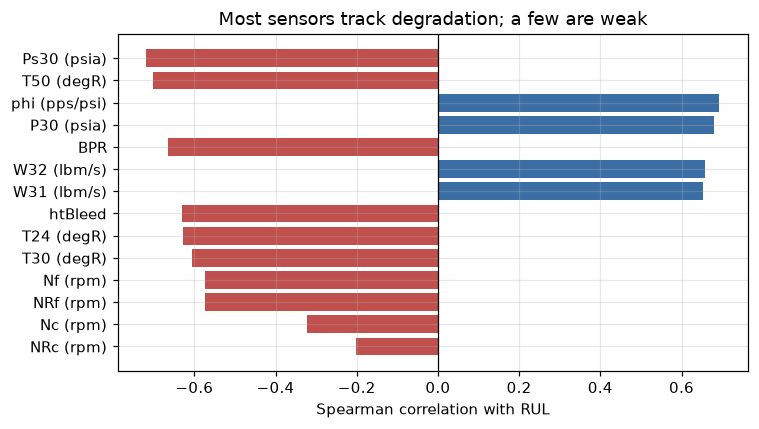

In [13]:
live = stats.index[~stats['flat']].tolist()
corr = train[live + ['rul']].corr(method='spearman')['rul'].drop('rul')
corr = corr.reindex(corr.abs().sort_values(ascending=False).index)

fig, ax = plt.subplots(figsize=(7, 4))
colors = ['#c0504d' if c < 0 else '#3b6ea5' for c in corr]
ax.barh([label(s) for s in corr.index][::-1], corr.values[::-1], color=colors[::-1])
ax.axvline(0, color='k', lw=0.8)
ax.set(xlabel='Spearman correlation with RUL', title='Most sensors track degradation; a few are weak')
fig.tight_layout(); fig.savefig(FIG / '02_sensor_correlation.png')
corr.round(3)

## 4. What does degradation look like?

Each sensor against RUL for 10 engines (thin lines), with a 10-cycle rolling mean. Read right to left: RUL falls to 0 at failure.

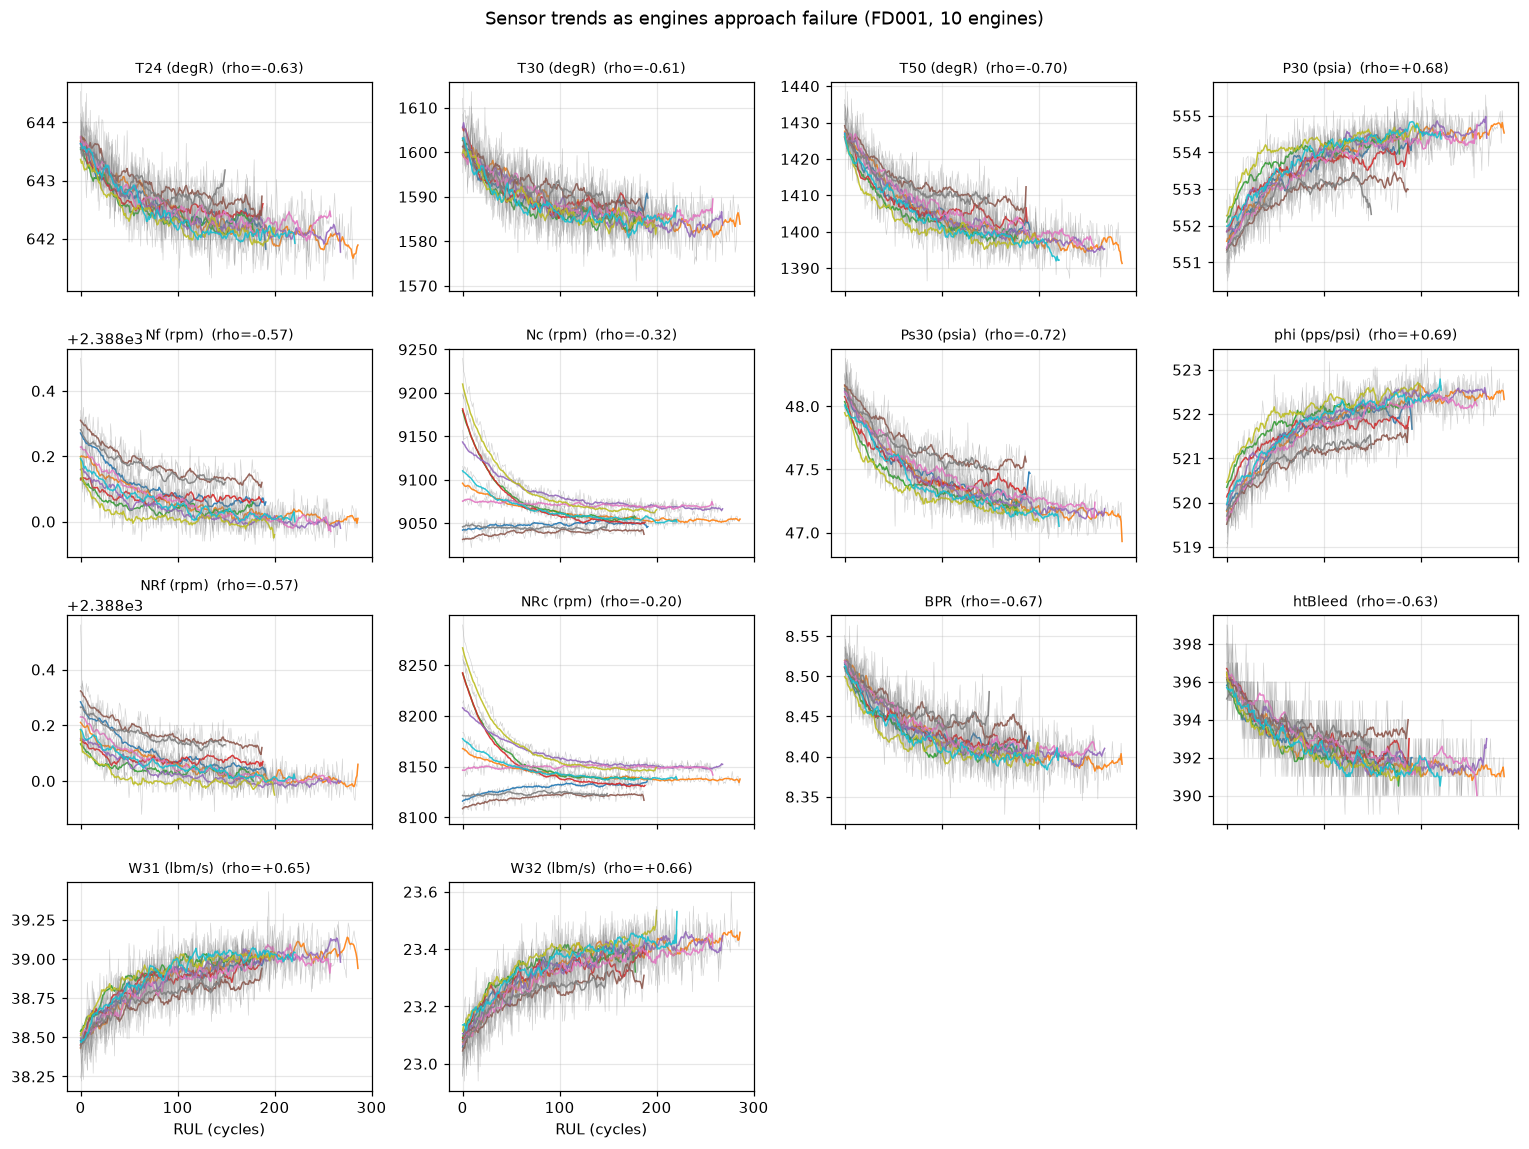

In [14]:
units = sorted(train['unit'].unique())[:10]
n = len(live); ncols = 4; nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(14, 2.6 * nrows), sharex=True)
for ax, s in zip(axes.flat, live):
    for u in units:
        d = train[train.unit == u]
        ax.plot(d['rul'], d[s], lw=0.4, alpha=0.35, color='grey')
        ax.plot(d['rul'], d[s].rolling(10, min_periods=1).mean(), lw=1, alpha=0.9)
    ax.set_title(f'{label(s)}  (rho={corr[s]:+.2f})', fontsize=9)
    ax.invert_xaxis()
for ax in axes.flat[n:]:
    ax.set_visible(False)
for ax in axes[-1]:
    ax.set_xlabel('RUL (cycles)')
fig.suptitle('Sensor trends as engines approach failure (FD001, 10 engines)', y=1.0)
fig.tight_layout(); fig.savefig(FIG / '03_sensor_trends.png', bbox_inches='tight')

## 5. Is degradation visible early?

Typical finding: sensors stay flat for most of life, then drift. That's why many papers cap RUL at ~125 cycles
(a *piecewise-linear* target) — the model can't know an engine with 300 cycles left from one with 200.

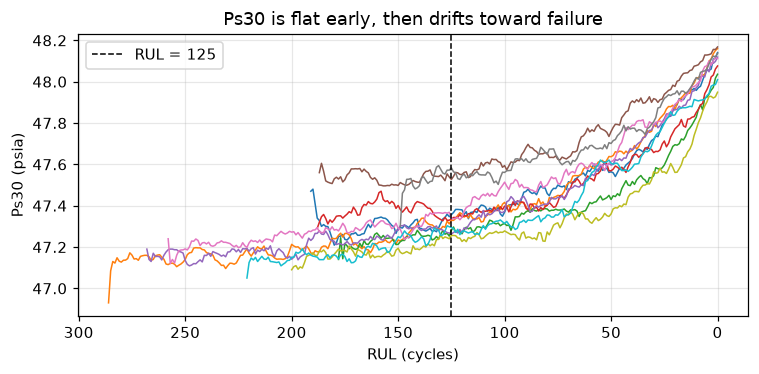

In [15]:
s = corr.index[0]
fig, ax = plt.subplots(figsize=(7, 3.5))
for u in units:
    d = train[train.unit == u]
    ax.plot(d['rul'], d[s].rolling(10, min_periods=1).mean(), lw=1)
ax.axvline(125, color='k', ls='--', lw=1, label='RUL = 125')
ax.invert_xaxis(); ax.legend()
ax.set(xlabel='RUL (cycles)', ylabel=label(s), title=f'{SENSORS[s][0]} is flat early, then drifts toward failure')
fig.tight_layout(); fig.savefig(FIG / '04_early_vs_late.png')

## 6. Result: sensors to keep

In [16]:
keep = [s for s in live if abs(corr[s]) >= 0.3]
weak = [s for s in live if abs(corr[s]) < 0.3]
summary = stats.loc[keep, ['tag', 'meaning']].assign(rho=corr[keep].round(3)).sort_values('rho', key=abs, ascending=False)
print('Flat (drop):', [SENSORS[s][0] for s in stats.index[stats['flat']]])
print('Weak (drop for now):', [SENSORS[s][0] for s in weak])
print('Keep:', [SENSORS[s][0] for s in summary.index])
summary.to_csv('../reports/sensors_selected.csv')
summary

Flat (drop): ['T2', 'P2', 'P15', 'epr', 'farB', 'Nf_dmd', 'PCNfR_dmd']
Weak (drop for now): ['NRc']
Keep: ['Ps30', 'T50', 'phi', 'P30', 'BPR', 'W32', 'W31', 'T24', 'htBleed', 'T30', 'Nf', 'NRf', 'Nc']


,tag,meaning,rho
s11,Ps30,HPC outlet static pressure,-0.718
s4,T50,LPT outlet total temperature,-0.702
s12,phi,Fuel flow / Ps30,0.693
s7,P30,HPC outlet total pressure,0.679
s15,BPR,Bypass ratio,-0.666
s21,W32,LPT coolant bleed,0.657
s20,W31,HPT coolant bleed,0.653
s2,T24,LPC outlet total temperature,-0.629
s17,htBleed,Bleed enthalpy,-0.629
s3,T30,HPC outlet total temperature,-0.606


### Next (Week 2)

The kept sensors are mostly **temperatures and pressures at the HPC outlet (T30, P30, Ps30) and LPT outlet (T50)**,
plus core speed and fuel flow — exactly the stations a cycle model predicts. Week 2 builds that 0D model and checks
that lowering HPC efficiency moves these sensors the same way the data does.